# 02 — Experimental evaluation: tutti i dataset

Questo notebook non genera goal e non avvia il feedback loop. Legge tutte le baseline in `output/top_down/` e i risultati in `output/top_down_bottom_up/`. La configurazione corrente include la completezza; eventuali risultati storici senza completezza e quelli nella cartella `output/top_down_bottom_up_discovery/` sono distinti mediante i metadati.

Confronta HLG e LLG con la ground truth mediante BERT e matching Hungarian, calcolando Precision, Recall e F1 per ogni metodo disponibile. Tutti i dataset registrati compaiono nella tabella di disponibilità; un risultato bottom-up assente non esclude la relativa baseline dalla valutazione. I confronti tra metodi richiedono entrambi i risultati.


Ogni esecuzione rilegge gli output correnti da disco e ricalcola le metriche sulle collezioni finali. Le cartelle storiche non sono incluse automaticamente. I CSV delle valutazioni precedenti non sono usati come ingresso. Avviare manualmente tutte le celle per aggiornare tabelle e grafico.


In [1]:
from pathlib import Path
import json
import hashlib
import os
import sys

os.environ.setdefault("HF_HUB_ETAG_TIMEOUT", "30")
os.environ.setdefault("HF_HUB_DOWNLOAD_TIMEOUT", "60")

import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.optimize import linear_sum_assignment
from tqdm.auto import tqdm
from transformers import AutoModel, AutoTokenizer

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

NOTEBOOK_DIR = PROJECT_ROOT / "notebook"
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

OUTPUT_ROOT = PROJECT_ROOT / "output"
TOP_DOWN_DIR = OUTPUT_ROOT / "top_down"
TOP_DOWN_BOTTOM_UP_DIR = OUTPUT_ROOT / "top_down_bottom_up"
BOTTOM_UP_ITERATIONS_DIR = OUTPUT_ROOT / "bottom_up_iterations"
BOTTOM_UP_COMPLETENESS_ITERATIONS_DIR = OUTPUT_ROOT / "bottom_up_iterations_discovery"  # Historical traces
EVALUATION_DIR = OUTPUT_ROOT / "evaluation" / "three_way_pipeline_comparison"
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)



from groundtruth import GROUNDTRUTH_BY_NAME

print("Project root:", PROJECT_ROOT)
print("Top-down directory:", TOP_DOWN_DIR)
print("Bottom-up outputs (profile from metadata):", TOP_DOWN_BOTTOM_UP_DIR)
print("Evaluation output:", EVALUATION_DIR)

c:\Users\agnes\Desktop\github\LLM_MultiAgentChain_GoalOrientedAPIAlignement\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project root: C:\Users\agnes\Desktop\github\LLM_MultiAgentChain_GoalOrientedAPIAlignement
Top-down directory: C:\Users\agnes\Desktop\github\LLM_MultiAgentChain_GoalOrientedAPIAlignement\output\top_down
Bottom-up outputs (profile from metadata): C:\Users\agnes\Desktop\github\LLM_MultiAgentChain_GoalOrientedAPIAlignement\output\top_down_bottom_up
Evaluation output: C:\Users\agnes\Desktop\github\LLM_MultiAgentChain_GoalOrientedAPIAlignement\output\evaluation\three_way_pipeline_comparison


## 1. Input e disponibilità

Sono inclusi tutti i dataset con baseline e ground truth. I risultati bottom-up richiedono collezioni finali utilizzabili, assenza di errore di esecuzione e corrispondenza esatta di descrizione e goal iniziali con la baseline confrontata. Output incompatibili o non verificabili sono segnalati, senza riassegnarli a un'altra baseline.

La tabella riporta disponibilità ed esclusioni; un risultato mancante non elimina la baseline dalla valutazione e non viene interpretato come una lista di goal vuota. I profili storici sono distinti tramite metadati, non dal solo nome della cartella.


La selezione comprende tutti i dataset registrati in `groundtruth.py`, senza filtri su nomi, convergenza o numero di iterazioni. Se manca una baseline, il notebook segnala il problema invece di valutare silenziosamente un sottoinsieme. Se manca un risultato bottom-up valido, il progetto rimane nelle tabelle con metriche BU mancanti, senza inventare valori o convertirli in zero; le medie indicano il numero effettivo di coppie disponibili.


In [2]:
# Track the exact source bytes read in this execution, including revised outputs.
input_hashes = {}


def load_json(path: Path):
    path = Path(path).resolve()
    raw = path.read_bytes()
    digest = hashlib.sha256(raw).hexdigest()
    previous = input_hashes.get(path)
    if previous is not None and previous != digest:
        raise RuntimeError(f"Input changed during evaluation; restart: {path}")
    input_hashes[path] = digest
    return json.loads(raw.decode("utf-8"))


def index_json_files(directory: Path, pattern: str):
    result = {}
    for path in sorted(directory.glob(pattern)):
        payload = load_json(path)
        dataset_name = payload.get("name")
        if not dataset_name:
            print(f"Skipping file without dataset name: {path}")
            continue
        if dataset_name in result:
            raise RuntimeError(
                f"More than one file found for dataset {dataset_name!r} in {directory}. "
                "Remove stale duplicates or narrow the file pattern."
            )
        result[dataset_name] = (path, payload)
    return result


def valid_goal_collection(value, key):
    items = value.get(key) if isinstance(value, dict) else value
    return isinstance(items, list) and all(
        isinstance(item, str) and bool(item.strip()) or isinstance(item, dict)
        and any(isinstance(item.get(field), str) and item[field].strip() for field in ("name", "description"))
        for item in items
    )


def baseline_comparison_error(payload):
    baseline = baseline_by_dataset.get(payload.get("name"))
    if baseline is None:
        return "Missing matching top-down baseline"
    changed = [key for key in ("description", "structuredHighLevelGoals", "structuredLowLevelGoals")
               if key not in payload or payload[key] != baseline[1].get(key)]
    return "Different or unverifiable input baseline: " + ", ".join(changed) if changed else None


def successful_run_indexes(profile_directories):
    """Use explicit profile metadata before the directory's default profile."""
    indexes = {False: {}, True: {}}
    skipped = []
    for directory, default_completeness in profile_directories:
        for path in sorted(Path(directory).glob('*.json')):
            try:
                payload = load_json(path)
            except (OSError, ValueError) as exc:
                skipped.append((str(path), f'Unreadable JSON: {exc}'))
                continue
            if not isinstance(payload, dict):
                skipped.append((str(path), 'Expected a JSON object'))
                continue
            name = payload.get('name')
            if not name:
                skipped.append((str(path), 'Missing dataset name'))
                continue
            if payload.get('bottomUpError'):
                skipped.append((name, payload['bottomUpError']))
                continue
            if not (valid_goal_collection(payload.get('finalHighLevelGoals'), 'goals')
                    and valid_goal_collection(payload.get('finalLowLevelGoals'), 'low_level_goals')):
                skipped.append((name, 'Missing or malformed final goal collections'))
                continue
            mismatch = baseline_comparison_error(payload)
            if mismatch:
                skipped.append((name, mismatch))
                continue
            profile = payload.get('bottomUpRunProfile')
            configured = (payload.get('bottomUpModelConfiguration') or {}).get('completenessAnalysisRequired', (payload.get('bottomUpModelConfiguration') or {}).get('hlgDiscoveryEnabled'))
            completeness = (
                profile in ('with_completeness', 'with_discovery')
                if profile in ('with_completeness', 'without_completeness', 'with_discovery', 'without_discovery')
                else configured if isinstance(configured, bool) else default_completeness
            )
            previous = indexes[completeness].get(name)
            if previous is not None:
                raise RuntimeError(
                    f'Duplicate successful runs for {name!r}, completeness={completeness}: '
                    f'{previous[0]} and {path}. Select one run before comparing.'
                )
            indexes[completeness][name] = (path, payload)
    return indexes[False], indexes[True], skipped

baseline_by_dataset = index_json_files(TOP_DOWN_DIR, "*_top_down.json")
baseline_hashes = {name: input_hashes[path.resolve()]
                   for name, (path, _) in baseline_by_dataset.items()}
combined_by_dataset, completeness_by_dataset, skipped_outputs = successful_run_indexes([
    (TOP_DOWN_BOTTOM_UP_DIR, True),
])

# The experiment covers the entire registered collection, without subset filters.
common_datasets = sorted(GROUNDTRUTH_BY_NAME)
if not common_datasets:
    raise RuntimeError("No datasets registered in groundtruth.py")
missing_baselines = sorted(set(common_datasets) - set(baseline_by_dataset))
if missing_baselines:
    raise RuntimeError(
        "Cannot evaluate the full collection: missing top-down baselines for "
        f"{missing_baselines}. No partial dataset selection will be used."
    )

# All registered datasets remain visible, even without a successful revised output.
dataset_availability_rows = []
for dataset_name in sorted(GROUNDTRUTH_BY_NAME):
    reasons = [str(reason) for name, reason in skipped_outputs if name == dataset_name]
    if dataset_name not in baseline_by_dataset:
        reasons.append("Missing top-down baseline")
    if dataset_name not in combined_by_dataset and dataset_name not in completeness_by_dataset:
        reasons.append("No successful bottom-up output available; baseline metrics remain included when available")
    dataset_availability_rows.append({
        "dataset": dataset_name,
        "baseline_available": dataset_name in baseline_by_dataset,
        "bottom_up_available": dataset_name in combined_by_dataset,
        "completeness_available": dataset_name in completeness_by_dataset,
        "notes": "; ".join(reasons),
    })
dataset_availability_df = pd.DataFrame(dataset_availability_rows)
print(f"Dataset sperimentali: {len(common_datasets)}; output esclusi: {len(skipped_outputs)}")
display(dataset_availability_df)

print("All registered projects are included:")
for index, name in enumerate(common_datasets, 1):
    print(f"  {index}/{len(common_datasets)} - {name}")
missing_revised = sorted(set(common_datasets) - set(combined_by_dataset) - set(completeness_by_dataset))
if missing_revised:
    print("Projects retained with unavailable bottom-up metrics (NaN):", missing_revised)


Dataset sperimentali: 12; output esclusi: 0


,dataset,baseline_available,bottom_up_available,completeness_available,notes
0,Assegno Unico Universale - SIA Project 24 25,True,False,True,
1,Calculator,True,False,True,
2,Ethical Purchasing Group - SIA Project 22 23,True,False,True,
3,Event Organization Portal - SIA Project 21 22,True,False,True,
4,Fitness Tracker,True,False,True,
5,Genome Nexus,True,False,True,
6,Gestao Hospital,True,False,True,
7,La Reine Marlene - SIA Project 23 24,True,False,True,
8,London Ambulance Service,True,False,True,
9,Planning Poker,True,False,True,


All registered projects are included:
  1/12 - Assegno Unico Universale - SIA Project 24 25
  2/12 - Calculator
  3/12 - Ethical Purchasing Group - SIA Project 22 23
  4/12 - Event Organization Portal - SIA Project 21 22
  5/12 - Fitness Tracker
  6/12 - Genome Nexus
  7/12 - Gestao Hospital
  8/12 - La Reine Marlene - SIA Project 23 24
  9/12 - London Ambulance Service
  10/12 - Planning Poker
  11/12 - Recycling
  12/12 - SIA Project 25 26


## 2. Estrazione delle collezioni di goal

La baseline usa le collezioni strutturate top-down. I due output bottom-up usano le collezioni finali restituite dall'orchestrator (`finalHighLevelGoals`, `finalLowLevelGoals`) e mantengono separato lo stato di convergenza dei due profili.

In [3]:
def goal_text(item) -> str:
    if item is None:
        return ""
    if isinstance(item, str):
        return item.strip()
    if isinstance(item, dict):
        name = item.get("name")
        if isinstance(name, str) and name.strip():
            return name.strip()
        description = item.get("description")
        if isinstance(description, str):
            return description.strip()
    return str(item).strip()


def extract_hlg(container):
    if container is None:
        return []
    items = container.get("goals", []) if isinstance(container, dict) else container
    return [text for item in items if (text := goal_text(item))]


def extract_llg(container):
    if container is None:
        return []
    items = container.get("low_level_goals", []) if isinstance(container, dict) else container
    return [text for item in items if (text := goal_text(item))]


def extract_cycle_status(payload):
    cycle = payload.get("globalGoalCycle") or {}
    raw_warnings = cycle.get("warnings")
    if raw_warnings is None:
        raw_warnings = [warning for trace in (cycle.get("iterations") or [])
                        for warning in (trace.get("warnings") or [])]
    warnings = [str(warning) for warning in raw_warnings]
    rewrite_limited_ids = {branch_id
        for iteration in (cycle.get("iterations") or [])
        for branch_id, verdict in (iteration.get("evaluations") or {}).items()
        if (verdict.get("high_level_evaluation") or {}).get("rewrite_limit_reached")}
    return {
        "converged": cycle.get("converged"),
        "has_warnings": bool(warnings),
        "warning_count": len(warnings),
        "warning_details": "\n".join(dict.fromkeys(warnings)),
        "stop_reason": cycle.get("stop_reason"),
        "completed_iterations": cycle.get("completed_iterations"),
        "forced_confirmation_count": len(cycle.get("forced_confirmed_branch_ids") or []),
        "rewrite_limit_applied_count": len(rewrite_limited_ids),
        "pending_llg_audit_count": len(cycle.get("pending_llg_audit_ids") or []),
        "critic_approved": bool(cycle.get("converged")) and not cycle.get("forced_confirmed_branch_ids") and not rewrite_limited_ids and not cycle.get("pending_llg_audit_ids"),
    }


states = {}
for dataset_name in common_datasets:
    _, baseline = baseline_by_dataset[dataset_name]
    combined = combined_by_dataset.get(dataset_name, (None, None))[1]
    completeness = completeness_by_dataset.get(dataset_name, (None, None))[1]
    gt = GROUNDTRUTH_BY_NAME[dataset_name]

    states[dataset_name] = {
        "reference_hlg": [str(x).strip() for x in gt["highLevelGoals"] if str(x).strip()],
        "reference_llg": [str(x).strip() for x in gt["lowLevelGoals"] if str(x).strip()],
        "top_down_hlg": extract_hlg(baseline.get("structuredHighLevelGoals") or baseline.get("highLevelGoals")),
        "top_down_llg": extract_llg(baseline.get("structuredLowLevelGoals") or baseline.get("lowLevelGoals")),
        "bottom_up_hlg": extract_hlg(combined.get("finalHighLevelGoals")) if combined is not None else None,
        "bottom_up_llg": extract_llg(combined.get("finalLowLevelGoals")) if combined is not None else None,
        "completeness_hlg": extract_hlg(completeness.get("finalHighLevelGoals")) if completeness is not None else None,
        "completeness_llg": extract_llg(completeness.get("finalLowLevelGoals")) if completeness is not None else None,
        "bottom_up_cycle_status": extract_cycle_status(combined) if combined is not None else {},
        "completeness_cycle_status": extract_cycle_status(completeness) if completeness is not None else {},
    }


## 3. Metrica BERT/Hungarian

La metrica rimane invariata: testo del nome del goal (descrizione come fallback), embedding `bert-base-uncased` con mean pooling sui token non mascherati, similarità coseno e matching Hungarian uno a uno. Si sommano le similarità assegnate almeno pari a 0,65 e si divide per il numero di goal generati (soft Precision) o di riferimento (soft Recall); F1 è la media armonica.

Non si applicano stemming, lemmatizzazione o filtri NLTK. La soglia è applicata dopo il matching e nessun parametro viene ottimizzato sui risultati. Collezioni realmente vuote producono zero; output assenti o non validi restano esclusi.


In [4]:
BERT_MODEL_NAME = "bert-base-uncased"
BERT_BATCH_SIZE = 16
SIMILARITY_THRESHOLD = 0.65

print(f"Loading {BERT_MODEL_NAME}...")
tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)
model = AutoModel.from_pretrained(BERT_MODEL_NAME)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()

print("Device:", device)

Loading bert-base-uncased...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1745.71it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Device: cpu


In [5]:
class PaperAlignedGoalEvaluator:
    def __init__(self, tokenizer, model, device, batch_size=16, similarity_threshold=0.65):
        self.tokenizer = tokenizer
        self.model = model
        self.device = device
        self.batch_size = batch_size
        self.embedding_cache = {}
        self.similarity_threshold = similarity_threshold

    def _encode_missing(self, raw_texts):
        missing = list(dict.fromkeys(text for text in raw_texts if text not in self.embedding_cache))
        if not missing:
            return

        total_batches = (len(missing) + self.batch_size - 1) // self.batch_size
        for start in tqdm(
            range(0, len(missing), self.batch_size),
            total=total_batches,
            desc="BERT batches",
        ):
            raw_batch = missing[start:start + self.batch_size]

            encoded_input = self.tokenizer(
                raw_batch,
                padding=True,
                truncation=True,
                return_tensors="pt",
            ).to(self.device)

            with torch.inference_mode():
                model_output = self.model(**encoded_input)

            token_embeddings = model_output.last_hidden_state
            attention_mask = encoded_input["attention_mask"]
            input_mask_expanded = (
                attention_mask.unsqueeze(-1)
                .expand(token_embeddings.size())
                .float()
            )

            sum_embeddings = torch.sum(token_embeddings * input_mask_expanded, dim=1)
            sum_mask = torch.clamp(input_mask_expanded.sum(dim=1), min=1e-9)
            pooled = (sum_embeddings / sum_mask).detach().cpu()

            for text, embedding in zip(raw_batch, pooled):
                self.embedding_cache[text] = embedding

    def encode_texts(self, texts):
        self._encode_missing(texts)
        return torch.stack([self.embedding_cache[text] for text in texts])

    def compute_similarity(self, generated_goals, reference_goals):
        gen_embeddings = self.encode_texts(generated_goals)
        ref_embeddings = self.encode_texts(reference_goals)
        gen_norm = torch.nn.functional.normalize(gen_embeddings, p=2, dim=1)
        ref_norm = torch.nn.functional.normalize(ref_embeddings, p=2, dim=1)
        return torch.mm(gen_norm, ref_norm.transpose(0, 1)).numpy()

    def calculate_soft_f1(self, preds, refs):
        if not preds or not refs:
            return {"precision": 0.0, "recall": 0.0, "f1": 0.0, "matched_goal_count": 0}

        sim_matrix = self.compute_similarity(preds, refs)
        row_ind, col_ind = linear_sum_assignment(-sim_matrix)
        matched_similarities = sim_matrix[row_ind, col_ind]
        accepted = matched_similarities[matched_similarities >= self.similarity_threshold]
        total_similarity = float(accepted.sum())

        precision = total_similarity / len(preds)
        recall = total_similarity / len(refs)
        f1 = 0.0 if precision + recall == 0 else 2 * precision * recall / (precision + recall)
        return {
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "matched_goal_count": int(len(accepted)),
        }


evaluator = PaperAlignedGoalEvaluator(
    tokenizer=tokenizer,
    model=model,
    device=device,
    batch_size=BERT_BATCH_SIZE,
    similarity_threshold=SIMILARITY_THRESHOLD,
)

## 4. Calcolo delle metriche finali

Le metriche sono calcolate sulle collezioni finali degli output correnti, rispetto alla stessa ground truth. I record completi sono esportati; le sezioni successive mostrano il confronto top-down / bottom-up per progetto e poi le medie.


La tabella completa riporta dataset, livello, metodo, cardinalita generate e di riferimento, Precision, Recall, F1, corrispondenze, goal non abbinati e stato della run. Le colonne del ciclo si riferiscono al risultato bottom-up: sulla baseline top-down restano non applicabili. Tutte le righe e le colonne sono visualizzate senza troncamento.


In [6]:
metric_rows = []

for dataset_name, s in states.items():
    for level, reference, top_down, bottom_up, completeness in (
        (
            "High-Level Goals",
            s["reference_hlg"],
            s["top_down_hlg"],
            s["bottom_up_hlg"],
            s["completeness_hlg"],
        ),
        (
            "Low-Level Goals",
            s["reference_llg"],
            s["top_down_llg"],
            s["bottom_up_llg"],
            s["completeness_llg"],
        ),
    ):
        for method, generated, status in (
            ("top_down", top_down, {}),
            ("top_down_plus_bottom_up", bottom_up, s["bottom_up_cycle_status"]),
            ("top_down_plus_bottom_up_plus_completeness", completeness, s["completeness_cycle_status"]),
        ):
            if generated is None:
                continue
            m = evaluator.calculate_soft_f1(generated, reference)
            metric_rows.append(
                {
                    "dataset": dataset_name,
                    "level": level,
                    "method": method,
                    "generated_goal_count": len(generated),
                    "reference_goal_count": len(reference),
                    "precision": m["precision"],
                    "recall": m["recall"],
                    "f1": m["f1"],
                    "matched_goal_count": m["matched_goal_count"],
                    "unmatched_generated_count": len(generated) - m["matched_goal_count"],
                    "cycle_converged": status.get("converged"),
                    "cycle_stop_reason": status.get("stop_reason"),
                    "cycle_completed_iterations": status.get("completed_iterations"),
                    "cycle_forced_confirmation_count": status.get("forced_confirmation_count", 0),
                    "cycle_critic_approved": status.get("critic_approved"),
                    "cycle_rewrite_limit_applied_count": status.get("rewrite_limit_applied_count", 0),
                    "cycle_pending_llg_audit_count": status.get("pending_llg_audit_count", 0),
                    "cycle_has_warnings": status.get("has_warnings"),
                    "cycle_warning_count": status.get("warning_count"),
                    "cycle_warning_details": status.get("warning_details"),
                }
            )

metrics_df = pd.DataFrame(metric_rows)
def display_full_table(frame):
    """Show every project and column without pandas truncation."""
    with pd.option_context("display.max_rows", None, "display.max_columns", None):
        display(frame.round(4))


print("Metriche finali per dataset, livello e metodo:")
final_metric_columns = [
    "dataset", "level", "method", "generated_goal_count", "reference_goal_count",
    "precision", "recall", "f1", "matched_goal_count", "unmatched_generated_count",
    "cycle_converged", "cycle_stop_reason", "cycle_completed_iterations",
    "cycle_has_warnings", "cycle_warning_count",
]
display_full_table(metrics_df[final_metric_columns].sort_values(
    ["dataset", "level", "method"]).reset_index(drop=True))


BERT batches: 100%|██████████| 1/1 [00:00<00:00, 12.99it/s]


Metriche finali per dataset, livello e metodo:


,dataset,level,method,generated_goal_count,reference_goal_count,precision,recall,f1,matched_goal_count,unmatched_generated_count,cycle_converged,cycle_stop_reason,cycle_completed_iterations,cycle_has_warnings,cycle_warning_count
0,Assegno Unico Universale - SIA Project 24 25,High-Level Goals,top_down,10,4,0.3201,0.8003,0.4573,4,6,None,NaN,NaN,None,NaN
1,Assegno Unico Universale - SIA Project 24 25,High-Level Goals,top_down_plus_bottom_up_plus_completeness,10,4,0.3201,0.8003,0.4573,4,6,True,ALL_BRANCHES_CONFIRMED,1.0,False,0.0
2,Assegno Unico Universale - SIA Project 24 25,Low-Level Goals,top_down,24,28,0.7757,0.6648,0.7160,24,0,None,NaN,NaN,None,NaN
3,Assegno Unico Universale - SIA Project 24 25,Low-Level Goals,top_down_plus_bottom_up_plus_completeness,24,28,0.7757,0.6648,0.7160,24,0,True,ALL_BRANCHES_CONFIRMED,1.0,False,0.0
4,Calculator,High-Level Goals,top_down,1,2,0.9594,0.4797,0.6396,1,0,None,NaN,NaN,None,NaN
5,Calculator,High-Level Goals,top_down_plus_bottom_up_plus_completeness,1,2,0.9594,0.4797,0.6396,1,0,True,ALL_BRANCHES_CONFIRMED,1.0,False,0.0
6,Calculator,Low-Level Goals,top_down,5,7,0.5842,0.4173,0.4868,4,1,None,NaN,NaN,None,NaN
7,Calculator,Low-Level Goals,top_down_plus_bottom_up_plus_completeness,5,7,0.5842,0.4173,0.4868,4,1,True,ALL_BRANCHES_CONFIRMED,1.0,False,0.0
8,Ethical Purchasing Group - SIA Project 22 23,High-Level Goals,top_down,10,4,0.3177,0.7944,0.4539,4,6,None,NaN,NaN,None,NaN
9,Ethical Purchasing Group - SIA Project 22 23,High-Level Goals,top_down_plus_bottom_up_plus_completeness,11,4,0.2889,0.7944,0.4237,4,7,False,NO_ACTIONS_REMAIN_WITH_WARNINGS,3.0,True,1.0


## 5. Confronto per progetto: HLG e LLG

Due tabelle separate, una per HLG e una per LLG, affiancano Precision, Recall e F1 di top-down (TD) e bottom-up (BU), con delta F1 = BU - TD e variazione in punti percentuali. Sono visibili tutti i progetti registrati in groundtruth.py; un risultato bottom-up mancante resta NaN. Se esistono entrambi i profili revisionati per un progetto, si usa quello con completezza, incluso nel bottom-up corrente.


Ogni tabella mostra anche convergenza BU, iterazioni completate, motivo di arresto, presenza e numero dei warning. I warning sono quelli registrati lungo la run: possono riguardare problemi intermedi poi risolti e non equivalgono automaticamente a mancata convergenza. I testi completi sono esportati nel CSV del confronto per progetto, nella colonna `cycle_warning_details`. Un output mancante ha stato non disponibile, non viene etichettato come non convergente o privo di warning.


Sono mostrate anche una tabella unica con cardinalita e delta di Precision, Recall e F1, e due viste ordinate dedicate ai miglioramenti e ai peggioramenti di F1. I casi invariati restano nella tabella completa; i dati mancanti non vengono classificati come regressioni.


In [7]:
indexed_metrics = {
    method: metrics_df[metrics_df["method"] == method].set_index(["dataset", "level"])
    for method in (
        "top_down", "top_down_plus_bottom_up", "top_down_plus_bottom_up_plus_completeness",
    )
}
comparison_rows = []
for dataset_name, level in indexed_metrics["top_down"].index:
    key = (dataset_name, level)
    available = {
        label: indexed_metrics[method].loc[key]
        for label, method in (
            ("top_down", "top_down"),
            ("bottom_up", "top_down_plus_bottom_up"),
            ("completeness", "top_down_plus_bottom_up_plus_completeness"),
        )
        if key in indexed_metrics[method].index
    }
    row = {"dataset": dataset_name, "level": level}
    for metric in ("generated_goal_count", "precision", "recall", "f1"):
        for label in ("top_down", "bottom_up", "completeness"):
            row[f"{label}_{metric}"] = available[label][metric] if label in available else float("nan")
        for target, source in (("bottom_up", "top_down"), ("completeness", "top_down"), ("completeness", "bottom_up")):
            row[f"delta_{target}_vs_{source}_{metric}"] = (
                available[target][metric] - available[source][metric]
                if target in available and source in available else float("nan")
            )
    for label in ("bottom_up", "completeness"):
        row[f"{label}_converged"] = available[label]["cycle_converged"] if label in available else None
        row[f"{label}_stop_reason"] = available[label]["cycle_stop_reason"] if label in available else None
    comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows)

def project_metric_comparison(metrics):
    keys = ["dataset", "level"]
    measures = ["generated_goal_count", "precision", "recall", "f1"]
    baseline = metrics[metrics["method"] == "top_down"][keys + measures]
    revised = metrics[metrics["method"].isin([
        "top_down_plus_bottom_up", "top_down_plus_bottom_up_plus_completeness",
    ])].copy()
    revised["profile_priority"] = revised["method"].map({
        "top_down_plus_bottom_up_plus_completeness": 0,
        "top_down_plus_bottom_up": 1,
    })
    revised = revised.sort_values("profile_priority").drop_duplicates(keys)
    status_columns = ["cycle_converged", "cycle_stop_reason", "cycle_completed_iterations",
                      "cycle_has_warnings", "cycle_warning_count", "cycle_warning_details"]
    result = baseline.merge(
        revised.reindex(columns=keys + measures + ["method"] + status_columns), on=keys, how="left",
        suffixes=("_top_down", "_bottom_up"), validate="one_to_one",
    ).rename(columns={"method": "bottom_up_profile"})
    result["delta_goal_count"] = result["generated_goal_count_bottom_up"] - result["generated_goal_count_top_down"]
    result["delta_precision"] = result["precision_bottom_up"] - result["precision_top_down"]
    result["delta_recall"] = result["recall_bottom_up"] - result["recall_top_down"]
    result["delta_f1"] = result["f1_bottom_up"] - result["f1_top_down"]
    result["delta_f1_pp"] = 100 * result["delta_f1"]
    return result.sort_values(keys).reset_index(drop=True)


comparison_metric_columns = [
    "precision_top_down", "recall_top_down", "f1_top_down",
    "precision_bottom_up", "recall_bottom_up", "f1_bottom_up",
    "delta_f1", "delta_f1_pp",
]
comparison_status_columns = ["cycle_converged", "cycle_completed_iterations", "cycle_stop_reason",
                             "cycle_has_warnings", "cycle_warning_count"]
comparison_column_labels = {
    "dataset": "Progetto", "dataset_count": "Dataset confrontati",
    "precision_top_down": "Precision TD", "recall_top_down": "Recall TD", "f1_top_down": "F1 TD",
    "precision_bottom_up": "Precision BU", "recall_bottom_up": "Recall BU", "f1_bottom_up": "F1 BU",
    "delta_f1": "Delta F1", "delta_f1_pp": "Delta F1 (pp)",
    "cycle_converged": "Convergenza BU", "cycle_completed_iterations": "Iterazioni BU",
    "cycle_stop_reason": "Motivo arresto BU", "cycle_has_warnings": "Warning BU",
    "cycle_warning_count": "N. warning",
}
project_comparison_df = project_metric_comparison(metrics_df)
# Full comparison in the established layout, followed by the HLG/LLG views.
detailed_comparison_columns = [
    "dataset", "level", "generated_goal_count_top_down", "generated_goal_count_bottom_up", "delta_goal_count",
    "precision_top_down", "precision_bottom_up", "delta_precision",
    "recall_top_down", "recall_bottom_up", "delta_recall",
    "f1_top_down", "f1_bottom_up", "delta_f1",
    *comparison_status_columns,
]
detailed_comparison_df = project_comparison_df[detailed_comparison_columns].rename(columns={
    "generated_goal_count_top_down": "top_down_goal_count",
    "generated_goal_count_bottom_up": "bottom_up_goal_count",
    **{f"{metric}_{method}": f"{method}_{metric}"
       for metric in ("precision", "recall", "f1") for method in ("top_down", "bottom_up")},
})
print("Confronto completo per progetto e livello (BU include la completezza quando disponibile):")
display_full_table(detailed_comparison_df)

for level, label in (("High-Level Goals", "HLG"), ("Low-Level Goals", "LLG")):
    print(f"{label} - confronto per progetto: top-down (TD) e bottom-up (BU)")
    table = project_comparison_df.loc[
        project_comparison_df["level"] == level,
        ["dataset", *comparison_metric_columns, *comparison_status_columns]].copy()
    for column in ("cycle_converged", "cycle_has_warnings"):
        table[column] = table[column].map({True: "Si", False: "No"}).fillna("n.d.")
    display_full_table(table.rename(columns=comparison_column_labels).reset_index(drop=True))

# Keep unchanged cases in the complete table; display improvements/regressions separately.
f1_change_tolerance = 1e-12
improved_f1_df = detailed_comparison_df[
    detailed_comparison_df["delta_f1"] > f1_change_tolerance
].sort_values("delta_f1", ascending=False).reset_index(drop=True)
worsened_f1_df = detailed_comparison_df[
    detailed_comparison_df["delta_f1"] < -f1_change_tolerance
].sort_values("delta_f1").reset_index(drop=True)
print("Righe in cui il bottom-up migliora F1:")
display_full_table(improved_f1_df)
print("Righe in cui il bottom-up peggiora F1:")
display_full_table(worsened_f1_df)


Confronto completo per progetto e livello (BU include la completezza quando disponibile):


,dataset,level,top_down_goal_count,bottom_up_goal_count,delta_goal_count,top_down_precision,bottom_up_precision,delta_precision,top_down_recall,bottom_up_recall,delta_recall,top_down_f1,bottom_up_f1,delta_f1,cycle_converged,cycle_completed_iterations,cycle_stop_reason,cycle_has_warnings,cycle_warning_count
0,Assegno Unico Universale - SIA Project 24 25,High-Level Goals,10,10,0,0.3201,0.3201,0.0000,0.8003,0.8003,0.0000,0.4573,0.4573,0.0000,True,1.0,ALL_BRANCHES_CONFIRMED,False,0.0
1,Assegno Unico Universale - SIA Project 24 25,Low-Level Goals,24,24,0,0.7757,0.7757,0.0000,0.6648,0.6648,0.0000,0.7160,0.7160,0.0000,True,1.0,ALL_BRANCHES_CONFIRMED,False,0.0
2,Calculator,High-Level Goals,1,1,0,0.9594,0.9594,0.0000,0.4797,0.4797,0.0000,0.6396,0.6396,0.0000,True,1.0,ALL_BRANCHES_CONFIRMED,False,0.0
3,Calculator,Low-Level Goals,5,5,0,0.5842,0.5842,0.0000,0.4173,0.4173,0.0000,0.4868,0.4868,0.0000,True,1.0,ALL_BRANCHES_CONFIRMED,False,0.0
4,Ethical Purchasing Group - SIA Project 22 23,High-Level Goals,10,11,1,0.3177,0.2889,-0.0289,0.7944,0.7944,0.0000,0.4539,0.4237,-0.0303,False,3.0,NO_ACTIONS_REMAIN_WITH_WARNINGS,True,1.0
5,Ethical Purchasing Group - SIA Project 22 23,Low-Level Goals,32,43,11,0.3442,0.2569,-0.0873,0.7868,0.7892,0.0023,0.4789,0.3877,-0.0913,False,3.0,NO_ACTIONS_REMAIN_WITH_WARNINGS,True,1.0
6,Event Organization Portal - SIA Project 21 22,High-Level Goals,8,7,-1,0.2939,0.3359,0.0420,0.5878,0.5878,0.0000,0.3919,0.4275,0.0356,True,8.0,ALL_BRANCHES_CONFIRMED,True,2.0
7,Event Organization Portal - SIA Project 21 22,Low-Level Goals,16,16,0,0.8057,0.8076,0.0020,0.4604,0.4615,0.0011,0.5860,0.5874,0.0014,True,8.0,ALL_BRANCHES_CONFIRMED,True,2.0
8,Fitness Tracker,High-Level Goals,5,5,0,0.6298,0.6298,0.0000,0.5249,0.5249,0.0000,0.5726,0.5726,0.0000,True,1.0,ALL_BRANCHES_CONFIRMED,False,0.0
9,Fitness Tracker,Low-Level Goals,10,10,0,0.6885,0.6885,0.0000,0.5296,0.5296,0.0000,0.5987,0.5987,0.0000,True,1.0,ALL_BRANCHES_CONFIRMED,False,0.0


HLG - confronto per progetto: top-down (TD) e bottom-up (BU)


,Progetto,Precision TD,Recall TD,F1 TD,Precision BU,Recall BU,F1 BU,Delta F1,Delta F1 (pp),Convergenza BU,Iterazioni BU,Motivo arresto BU,Warning BU,N. warning
0,Assegno Unico Universale - SIA Project 24 25,0.3201,0.8003,0.4573,0.3201,0.8003,0.4573,0.0000,0.0000,Si,1.0,ALL_BRANCHES_CONFIRMED,No,0.0
1,Calculator,0.9594,0.4797,0.6396,0.9594,0.4797,0.6396,0.0000,0.0000,Si,1.0,ALL_BRANCHES_CONFIRMED,No,0.0
2,Ethical Purchasing Group - SIA Project 22 23,0.3177,0.7944,0.4539,0.2889,0.7944,0.4237,-0.0303,-3.0262,No,3.0,NO_ACTIONS_REMAIN_WITH_WARNINGS,Si,1.0
3,Event Organization Portal - SIA Project 21 22,0.2939,0.5878,0.3919,0.3359,0.5878,0.4275,0.0356,3.5623,Si,8.0,ALL_BRANCHES_CONFIRMED,Si,2.0
4,Fitness Tracker,0.6298,0.5249,0.5726,0.6298,0.5249,0.5726,0.0000,0.0000,Si,1.0,ALL_BRANCHES_CONFIRMED,No,0.0
5,Genome Nexus,0.3375,0.7876,0.4726,0.3375,0.7876,0.4726,0.0000,0.0000,Si,1.0,ALL_BRANCHES_CONFIRMED,No,0.0
6,Gestao Hospital,0.5184,0.7776,0.6221,0.5009,0.7513,0.6011,-0.0210,-2.1018,Si,2.0,ALL_BRANCHES_CONFIRMED,No,0.0
7,La Reine Marlene - SIA Project 23 24,0.7732,0.6185,0.6873,0.7732,0.6185,0.6873,0.0000,0.0000,No,5.0,NO_ACTIONS_REMAIN_WITH_WARNINGS,Si,9.0
8,London Ambulance Service,0.3686,0.7371,0.4914,0.3686,0.7371,0.4914,0.0000,0.0000,Si,3.0,ALL_BRANCHES_CONFIRMED,No,0.0
9,Planning Poker,0.4553,0.2732,0.3415,0.4563,0.2738,0.3422,0.0007,0.0743,No,6.0,NO_ACTIONS_REMAIN_WITH_WARNINGS,Si,4.0


LLG - confronto per progetto: top-down (TD) e bottom-up (BU)


,Progetto,Precision TD,Recall TD,F1 TD,Precision BU,Recall BU,F1 BU,Delta F1,Delta F1 (pp),Convergenza BU,Iterazioni BU,Motivo arresto BU,Warning BU,N. warning
0,Assegno Unico Universale - SIA Project 24 25,0.7757,0.6648,0.7160,0.7757,0.6648,0.7160,0.0000,0.0000,Si,1.0,ALL_BRANCHES_CONFIRMED,No,0.0
1,Calculator,0.5842,0.4173,0.4868,0.5842,0.4173,0.4868,0.0000,0.0000,Si,1.0,ALL_BRANCHES_CONFIRMED,No,0.0
2,Ethical Purchasing Group - SIA Project 22 23,0.3442,0.7868,0.4789,0.2569,0.7892,0.3877,-0.0913,-9.1285,No,3.0,NO_ACTIONS_REMAIN_WITH_WARNINGS,Si,1.0
3,Event Organization Portal - SIA Project 21 22,0.8057,0.4604,0.5860,0.8076,0.4615,0.5874,0.0014,0.1423,Si,8.0,ALL_BRANCHES_CONFIRMED,Si,2.0
4,Fitness Tracker,0.6885,0.5296,0.5987,0.6885,0.5296,0.5987,0.0000,0.0000,Si,1.0,ALL_BRANCHES_CONFIRMED,No,0.0
5,Genome Nexus,0.8747,0.2333,0.3683,0.8747,0.2333,0.3683,0.0000,0.0000,Si,1.0,ALL_BRANCHES_CONFIRMED,No,0.0
6,Gestao Hospital,0.6990,0.5825,0.6355,0.6990,0.5825,0.6355,0.0000,0.0000,Si,2.0,ALL_BRANCHES_CONFIRMED,No,0.0
7,La Reine Marlene - SIA Project 23 24,0.7099,0.4896,0.5795,0.7099,0.4896,0.5795,-0.0000,-0.0000,No,5.0,NO_ACTIONS_REMAIN_WITH_WARNINGS,Si,9.0
8,London Ambulance Service,0.3864,0.7729,0.5153,0.3864,0.7729,0.5153,0.0000,0.0000,Si,3.0,ALL_BRANCHES_CONFIRMED,No,0.0
9,Planning Poker,0.7625,0.1386,0.2346,0.7625,0.1386,0.2346,0.0000,0.0000,No,6.0,NO_ACTIONS_REMAIN_WITH_WARNINGS,Si,4.0


Righe in cui il bottom-up migliora F1:


,dataset,level,top_down_goal_count,bottom_up_goal_count,delta_goal_count,top_down_precision,bottom_up_precision,delta_precision,top_down_recall,bottom_up_recall,delta_recall,top_down_f1,bottom_up_f1,delta_f1,cycle_converged,cycle_completed_iterations,cycle_stop_reason,cycle_has_warnings,cycle_warning_count
0,SIA Project 25 26,Low-Level Goals,13,28,15,0.7311,0.7529,0.0218,0.3066,0.6801,0.3735,0.4320,0.7146,0.2826,True,3.0,ALL_BRANCHES_CONFIRMED,False,0.0
1,SIA Project 25 26,High-Level Goals,8,8,0,0.4530,0.5387,0.0857,0.3624,0.4310,0.0686,0.4027,0.4789,0.0762,True,3.0,ALL_BRANCHES_CONFIRMED,False,0.0
2,Event Organization Portal - SIA Project 21 22,High-Level Goals,8,7,-1,0.2939,0.3359,0.0420,0.5878,0.5878,0.0000,0.3919,0.4275,0.0356,True,8.0,ALL_BRANCHES_CONFIRMED,True,2.0
3,Event Organization Portal - SIA Project 21 22,Low-Level Goals,16,16,0,0.8057,0.8076,0.0020,0.4604,0.4615,0.0011,0.5860,0.5874,0.0014,True,8.0,ALL_BRANCHES_CONFIRMED,True,2.0
4,Planning Poker,High-Level Goals,3,3,0,0.4553,0.4563,0.0010,0.2732,0.2738,0.0006,0.3415,0.3422,0.0007,False,6.0,NO_ACTIONS_REMAIN_WITH_WARNINGS,True,4.0


Righe in cui il bottom-up peggiora F1:


,dataset,level,top_down_goal_count,bottom_up_goal_count,delta_goal_count,top_down_precision,bottom_up_precision,delta_precision,top_down_recall,bottom_up_recall,delta_recall,top_down_f1,bottom_up_f1,delta_f1,cycle_converged,cycle_completed_iterations,cycle_stop_reason,cycle_has_warnings,cycle_warning_count
0,Ethical Purchasing Group - SIA Project 22 23,Low-Level Goals,32,43,11,0.3442,0.2569,-0.0873,0.7868,0.7892,0.0023,0.4789,0.3877,-0.0913,False,3.0,NO_ACTIONS_REMAIN_WITH_WARNINGS,True,1.0
1,Ethical Purchasing Group - SIA Project 22 23,High-Level Goals,10,11,1,0.3177,0.2889,-0.0289,0.7944,0.7944,0.0000,0.4539,0.4237,-0.0303,False,3.0,NO_ACTIONS_REMAIN_WITH_WARNINGS,True,1.0
2,Gestao Hospital,High-Level Goals,6,6,0,0.5184,0.5009,-0.0175,0.7776,0.7513,-0.0263,0.6221,0.6011,-0.0210,True,2.0,ALL_BRANCHES_CONFIRMED,False,0.0
3,La Reine Marlene - SIA Project 23 24,Low-Level Goals,20,20,0,0.7099,0.7099,-0.0000,0.4896,0.4896,-0.0000,0.5795,0.5795,-0.0000,False,5.0,NO_ACTIONS_REMAIN_WITH_WARNINGS,True,9.0


## 6. Medie del confronto: HLG e LLG

Dopo le tabelle per progetto, due riepiloghi riportano le medie di Precision, Recall e F1 per TD e BU, il delta F1 medio e il numero di dataset confrontati. Le medie dei due metodi usano esattamente gli stessi progetti con entrambe le misure disponibili: ogni progetto ha uguale peso. Il delta F1 medio coincide con la media dei delta individuali sulle stesse coppie. Le righe senza risultato revisionato non sono trattate come punteggi zero.


Le macro-medie sono presentate anche nel formato lungo per livello/metodo e in una tabella pivot con Precision, Recall e F1 affiancate per top-down e bottom-up. Tutti questi riepiloghi usano le stesse coppie di progetti della tabella dei delta.


In [8]:
macro_df = (
    metrics_df
    .groupby(["level", "method"], as_index=False)
    .agg(precision=("precision", "mean"), recall=("recall", "mean"),
         f1=("f1", "mean"), dataset_count=("dataset", "nunique"))
)

# Paired macro summaries: source and target always use the same dataset cohort.
paired_macro_rows = []
for source_method, target_method in (
    ("top_down", "top_down_plus_bottom_up"),
    ("top_down", "top_down_plus_bottom_up_plus_completeness"),
    ("top_down_plus_bottom_up", "top_down_plus_bottom_up_plus_completeness"),
):
    pairs = metrics_df[metrics_df["method"] == source_method].merge(
        metrics_df[metrics_df["method"] == target_method],
        on=["dataset", "level"], suffixes=("_source", "_target"), validate="one_to_one",
    )
    for level, group in pairs.groupby("level"):
        row = {"level": level, "source_method": source_method, "target_method": target_method,
               "dataset_count": group["dataset"].nunique(), "datasets": "; ".join(sorted(group["dataset"]))}
        for metric in ("precision", "recall", "f1"):
            row[f"source_{metric}"] = group[f"{metric}_source"].mean()
            row[f"target_{metric}"] = group[f"{metric}_target"].mean()
            row[f"delta_{metric}"] = row[f"target_{metric}"] - row[f"source_{metric}"]
        paired_macro_rows.append(row)
paired_macro_df = pd.DataFrame(paired_macro_rows, columns=[
    "level", "source_method", "target_method", "dataset_count", "datasets",
    *[f"{prefix}_{metric}" for metric in ("precision", "recall", "f1") for prefix in ("source", "target", "delta")],
])


# Macro means on exactly the project pairs shown in the preceding tables.
def mean_metric_comparison(project_comparisons):
    paired = project_comparisons.dropna(subset=[
        "precision_top_down", "recall_top_down", "f1_top_down",
        "precision_bottom_up", "recall_bottom_up", "f1_bottom_up",
    ])
    result = paired.groupby("level", as_index=False).agg(
        dataset_count=("dataset", "nunique"),
        **{column: (column, "mean") for column in comparison_metric_columns
           if column not in ("delta_f1", "delta_f1_pp")},
        bottom_up_profiles=("bottom_up_profile", lambda values: "; ".join(sorted(set(values)))),
    )
    result["delta_f1"] = result["f1_bottom_up"] - result["f1_top_down"]
    result["delta_f1_pp"] = 100 * result["delta_f1"]
    return result[["level", "dataset_count", *comparison_metric_columns, "bottom_up_profiles"]]


mean_comparison_df = mean_metric_comparison(project_comparison_df)
# The long and pivoted macro views use the same paired projects as the deltas.
macro_comparison_rows = []
for row in mean_comparison_df.to_dict("records"):
    for method in ("top_down", "bottom_up"):
        macro_comparison_rows.append({
            "level": row["level"], "method": method, "dataset_count": row["dataset_count"],
            **{metric: row[f"{metric}_{method}"] for metric in ("precision", "recall", "f1")},
        })
macro_comparison_df = pd.DataFrame(macro_comparison_rows, columns=[
    "level", "method", "dataset_count", "precision", "recall", "f1",
])
print("Macro-medie per livello e metodo (stessi dataset):")
display_full_table(macro_comparison_df)
macro_pivot = macro_comparison_df.pivot(
    index="level", columns="method", values=["precision", "recall", "f1"],
).reindex(columns=[(metric, method) for metric in ("precision", "recall", "f1")
                  for method in ("top_down", "bottom_up")])
print("Macro comparison: top-down e bottom-up affiancati")
display_full_table(macro_pivot)

for level, label in (("High-Level Goals", "HLG"), ("Low-Level Goals", "LLG")):
    print(f"{label} - medie sui progetti appaiati; delta F1 = BU - TD")
    table = mean_comparison_df.loc[
        mean_comparison_df["level"] == level, ["dataset_count", *comparison_metric_columns]]
    display_full_table(table.rename(columns=comparison_column_labels).reset_index(drop=True))

# Retain the existing focused F1 export, derived from the same paired summary.
f1_mean_delta_df = mean_comparison_df[[
    "level", "dataset_count", "f1_top_down", "f1_bottom_up", "delta_f1", "delta_f1_pp", "bottom_up_profiles",
]].rename(columns={"f1_top_down": "top_down_mean_f1", "f1_bottom_up": "bottom_up_mean_f1",
                   "delta_f1": "delta_mean_f1", "delta_f1_pp": "delta_mean_f1_pp"})


Macro-medie per livello e metodo (stessi dataset):


,level,method,dataset_count,precision,recall,f1
0,High-Level Goals,top_down,12,0.4993,0.6278,0.5159
1,High-Level Goals,bottom_up,12,0.5061,0.6313,0.5210
2,Low-Level Goals,top_down,12,0.6746,0.4827,0.5131
3,Low-Level Goals,bottom_up,12,0.6693,0.5141,0.5292


Macro comparison: top-down e bottom-up affiancati


precision             recall                 f1          
method            top_down bottom_up top_down bottom_up top_down bottom_up
level                                                                     
High-Level Goals    0.4993    0.5061   0.6278    0.6313   0.5159    0.5210
Low-Level Goals     0.6746    0.6693   0.4827    0.5141   0.5131    0.5292

HLG - medie sui progetti appaiati; delta F1 = BU - TD


,Dataset confrontati,Precision TD,Recall TD,F1 TD,Precision BU,Recall BU,F1 BU,Delta F1,Delta F1 (pp)
0,12,0.4993,0.6278,0.5159,0.5061,0.6313,0.521,0.0051,0.5104


LLG - medie sui progetti appaiati; delta F1 = BU - TD


,Dataset confrontati,Precision TD,Recall TD,F1 TD,Precision BU,Recall BU,F1 BU,Delta F1,Delta F1 (pp)
0,12,0.6746,0.4827,0.5131,0.6693,0.5141,0.5292,0.0161,1.6062


## 7. Traiettorie coerenti per tutti i dataset

L’iterazione 0 usa la baseline verificata. Si preferiscono gli snapshot incorporati nel risultato; i file esterni sono un fallback storico e devono terminare alla stessa iterazione e agli stessi goal finali del risultato. Checkpoint incompleti non sono valutati. Trace mancanti o incoerenti sono segnalati senza ricostruire una traiettoria artificiale.

Tutti i dataset rimangono visibili, almeno come punto della baseline. Le macro-medie per iterazione indicano il numero dei dataset effettivamente presenti; le linee terminano all’ultima iterazione registrata. Il solo grafico dettagliato a sei pannelli compare alla fine.


Se i trace non sono disponibili o non coincidono con il risultato corrente, il grafico conserva baseline e punto finale usando le metriche finali appena calcolate; il motivo viene segnalato senza ricostruire iterazioni intermedie.


In [9]:
def resolve_iteration_directory(combined_payload, fallback_root):
    configured = combined_payload.get("evaluationOutputDirectory")
    candidates = []
    if configured:
        configured_path = Path(configured)
        candidates.append(configured_path)
        candidates.append(fallback_root / configured_path.name)

    baseline_name = combined_payload.get("baselineSourceFile")
    if baseline_name:
        baseline_stem = Path(baseline_name).stem
        if baseline_stem.endswith("_top_down"):
            baseline_stem = baseline_stem[:-len("_top_down")]
        candidates.append(fallback_root / baseline_stem)

    for candidate in candidates:
        if candidate.is_dir():
            return candidate
    return None


def completed_run_traces(payload, fallback_root):
    """Prefer snapshots belonging to this output; never combine different runs."""
    cycle = payload.get("globalGoalCycle") or {}
    traces = cycle.get("iterations") or []
    if not traces:
        directory = resolve_iteration_directory(payload, fallback_root)
        if directory is None:
            raise ValueError("No iteration snapshots available for this run")
        traces = []
        for path in sorted(directory.glob("iteration_*.json")):
            trace = load_json(path)
            trace.setdefault("iteration", int(path.stem.rsplit("_", 1)[-1]))
            traces.append(trace)
    completed = sorted((t for t in traces if t.get("checkpoint_complete") is not False),
                       key=lambda t: int(t["iteration"]))
    ids = [int(t["iteration"]) for t in completed]
    if not ids or len(set(ids)) != len(ids) or min(ids) < 1:
        raise ValueError("Missing, duplicate or invalid completed iteration numbers")
    for trace in completed:
        if not (valid_goal_collection(trace.get("high_level_goals"), "goals")
                and valid_goal_collection(trace.get("low_level_goals"), "low_level_goals")):
            raise ValueError("An iteration snapshot has missing or malformed goal collections")
    last = completed[-1]
    expected_iteration = cycle.get("completed_iterations")
    if expected_iteration is not None and int(last["iteration"]) != int(expected_iteration):
        raise ValueError("Iteration snapshots do not end at this run's final iteration")
    if (last["high_level_goals"] != payload["finalHighLevelGoals"]
            or last["low_level_goals"] != payload["finalLowLevelGoals"]):
        raise ValueError("Final iteration snapshot differs from the saved final goals")
    return completed


def final_run_metric_rows(dataset_name, profile, payload):
    """Keep the current final result visible even without usable iteration traces."""
    completed = (payload.get("globalGoalCycle") or {}).get("completed_iterations")
    iteration = int(completed) if completed is not None else 1
    if iteration < 1:
        raise ValueError("A revised output must have a positive final iteration")
    rows = metrics_df[(metrics_df["dataset"] == dataset_name) & (metrics_df["method"] == profile)]
    if len(rows) != 2 or set(rows["level"]) != {"High-Level Goals", "Low-Level Goals"}:
        raise ValueError(f"Missing final metrics for {dataset_name} [{profile}]")
    fields = ("generated_goal_count", "reference_goal_count", "precision", "recall", "f1", "matched_goal_count")
    return [{"dataset": dataset_name, "profile": profile, "level": row["level"],
             "iteration": iteration, "state": "bottom_up_final",
             **{key: row[key] for key in fields}}
            for row in rows.to_dict("records")]


iteration_metric_rows = []
missing_iteration_traces = []

for dataset_name, s in states.items():
    available_profiles = [
        (profile, indexed_outputs, trace_root)
        for profile, indexed_outputs, trace_root in (
            ("top_down_plus_bottom_up", combined_by_dataset, BOTTOM_UP_ITERATIONS_DIR),
            ("top_down_plus_bottom_up_plus_completeness", completeness_by_dataset, BOTTOM_UP_COMPLETENESS_ITERATIONS_DIR),
        )
        if dataset_name in indexed_outputs
    ]
    # Keep every dataset visible, even when no successful bottom-up output exists.
    if not available_profiles:
        available_profiles = [("top_down_only", {}, None)]
    for profile, indexed_outputs, trace_root in available_profiles:
        # Iteration 0 is the top-down baseline for this available trajectory.
        for level, reference, generated in (
            ("High-Level Goals", s["reference_hlg"], s["top_down_hlg"]),
            ("Low-Level Goals", s["reference_llg"], s["top_down_llg"]),
        ):
            m = evaluator.calculate_soft_f1(generated, reference)
            iteration_metric_rows.append({
                "dataset": dataset_name, "profile": profile, "level": level,
                "iteration": 0, "state": "top_down_baseline",
                "generated_goal_count": len(generated),
                "reference_goal_count": len(reference), **m,
            })

        if profile == "top_down_only":
            missing_iteration_traces.append(f"{dataset_name} [solo baseline]")
            continue

        _, combined = indexed_outputs[dataset_name]
        try:
            traces = completed_run_traces(combined, trace_root)
        except (OSError, ValueError, TypeError, KeyError) as exc:
            missing_iteration_traces.append(f"{dataset_name} [{profile}]: {exc}")
            iteration_metric_rows.extend(final_run_metric_rows(dataset_name, profile, combined))
            continue
        for trace in traces:
            iteration = int(trace["iteration"])
            for level, reference, generated in (
                ("High-Level Goals", s["reference_hlg"], extract_hlg(trace.get("high_level_goals"))),
                ("Low-Level Goals", s["reference_llg"], extract_llg(trace.get("low_level_goals"))),
            ):
                m = evaluator.calculate_soft_f1(generated, reference)
                iteration_metric_rows.append({
                    "dataset": dataset_name, "profile": profile, "level": level,
                    "iteration": iteration, "state": "bottom_up_iteration",
                    "generated_goal_count": len(generated),
                    "reference_goal_count": len(reference), **m,
                })

iteration_metrics_df = pd.DataFrame(iteration_metric_rows).sort_values(
    ["profile", "level", "iteration", "dataset"]
).reset_index(drop=True)

iteration_macro_df = (
    iteration_metrics_df
    .groupby(["profile", "level", "iteration"], as_index=False)
    .agg(
        precision=("precision", "mean"),
        recall=("recall", "mean"),
        f1=("f1", "mean"),
        dataset_count=("dataset", "nunique"),
    )
    .sort_values(["profile", "level", "iteration"])
)

if missing_iteration_traces:
    print("Dataset senza trace di iterazione:", missing_iteration_traces)


# Chart location is defined before export; rendering is the last notebook step.
iteration_dataset_chart_path = EVALUATION_DIR / "iteration_metric_trend_by_dataset.png"


BERT batches:   0%|          | 0/1 [00:00<?, ?it/s]

BERT batches: 100%|██████████| 1/1 [00:00<00:00, 28.57it/s]


## 8. Export essenziale

Sono salvati disponibilità, metriche individuali, delta, macro-medie descrittive, confronti macro su coppie di dataset identiche e traiettorie. Il riepilogo JSON conserva sorgenti, hash della baseline, modelli/politiche disponibili, esclusioni e definizione della metrica. I nomi dei CSV esistenti restano invariati; si aggiunge `paired_macro_summary.csv`.


Prima di esportare vengono verificati gli hash di tutti gli input letti, inclusi gli output bottom-up: se un file cambia durante il calcolo, occorre riavviare la valutazione. Il riepilogo registra anche hash degli output e verifiche LLG ancora pendenti.


In [10]:
changed_inputs = [str(path) for path, digest in input_hashes.items()
                  if not path.is_file() or hashlib.sha256(path.read_bytes()).hexdigest() != digest]
if changed_inputs:
    raise RuntimeError(f"Inputs changed during evaluation; restart before exporting: {changed_inputs}")

# Export data used by the comparisons; retain established filenames.
tables = {
    "dataset_availability_csv": ("dataset_availability.csv", dataset_availability_df),
    "metrics_csv": ("three_way_pipeline_metrics.csv", metrics_df),
    "deltas_csv": ("three_way_pipeline_deltas.csv", comparison_df),
    "macro_summary_csv": ("three_way_pipeline_macro_summary.csv", macro_df),
    "paired_macro_summary_csv": ("paired_macro_summary.csv", paired_macro_df),
    "mean_f1_delta_csv": ("mean_f1_delta.csv", f1_mean_delta_df),
    "project_metrics_comparison_csv": ("project_metrics_comparison.csv", project_comparison_df),
    "mean_metrics_comparison_csv": ("mean_metrics_comparison.csv", mean_comparison_df),
    "project_metric_deltas_csv": ("project_metric_deltas.csv", detailed_comparison_df),
    "f1_improved_csv": ("f1_improved.csv", improved_f1_df),
    "f1_worsened_csv": ("f1_worsened.csv", worsened_f1_df),
    "macro_comparison_csv": ("macro_comparison.csv", macro_comparison_df),
    "iteration_metrics_csv": ("iteration_metrics.csv", iteration_metrics_df),
    "iteration_macro_summary_csv": ("iteration_macro_summary.csv", iteration_macro_df),
}
output_paths = {}
for key, (filename, table) in tables.items():
    path = EVALUATION_DIR / filename
    table.to_csv(path, index=False)
    output_paths[key] = str(path)

sources = []
for dataset in common_datasets:
    baseline_path, _ = baseline_by_dataset[dataset]
    runs = {}
    for profile, indexed in (("bottom_up", combined_by_dataset), ("completeness", completeness_by_dataset)):
        if dataset in indexed:
            path, payload = indexed[dataset]
            config = payload.get("bottomUpModelConfiguration") or {}
            runs[profile] = {"file": str(path), "sha256": input_hashes[path.resolve()],
                             "policy": config.get("pipelinePolicyVersion"),
                             "generator": config.get("generatorModel"), "critics": config.get("evaluatorModels")}
    sources.append({"dataset": dataset, "baseline_file": str(baseline_path),
                    "baseline_sha256": baseline_hashes[dataset], "runs": runs})

summary = {
    "datasets": common_datasets,
    "registered_datasets": sorted(GROUNDTRUTH_BY_NAME),
    "dataset_availability": dataset_availability_rows,
    "datasets_by_method": {method: sorted(group["dataset"].unique()) for method, group in metrics_df.groupby("method")},
    "sources": sources,
    "skipped_outputs": skipped_outputs,
    "missing_iteration_traces": missing_iteration_traces,
    "selection_policy": "all registered baselines; current revised outputs only from output/top_down_bottom_up; final collections only; identical input baseline; paired dataset means",
    "metric": {
        "embedding_model": BERT_MODEL_NAME,
        "pooling": "attention-mask mean pooling",
        "goal_text": "name when present; description fallback",
        "matching": f"Hungarian one-to-one assignment; retain cosine similarities >= {SIMILARITY_THRESHOLD}",
        "scoring": "sum of accepted similarities divided by generated/reference goal counts; harmonic F1",
        "preprocessing": "Raw goal text; no stemming or lemmatization",
        "iteration_aggregation": "completed snapshots matching the saved final goals; baseline and final metrics fallback if traces are unavailable; means report dataset counts",
    },
    "outputs": {**output_paths, "iteration_dataset_trend_chart": str(iteration_dataset_chart_path)},
}
summary_path = EVALUATION_DIR / "evaluation_summary.json"
summary_path.write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Exported {len(tables)} CSV tables and evaluation_summary.json to {EVALUATION_DIR}")


Exported 14 CSV tables and evaluation_summary.json to C:\Users\agnes\Desktop\github\LLM_MultiAgentChain_GoalOrientedAPIAlignement\output\evaluation\three_way_pipeline_comparison


## 9. Grafico finale: tutti i dataset

I sei pannelli mostrano Recall, Precision e F1 per HLG e LLG. Ogni dataset mantiene lo stesso colore e simbolo; la legenda distingue i profili disponibili e i dataset con la sola baseline.


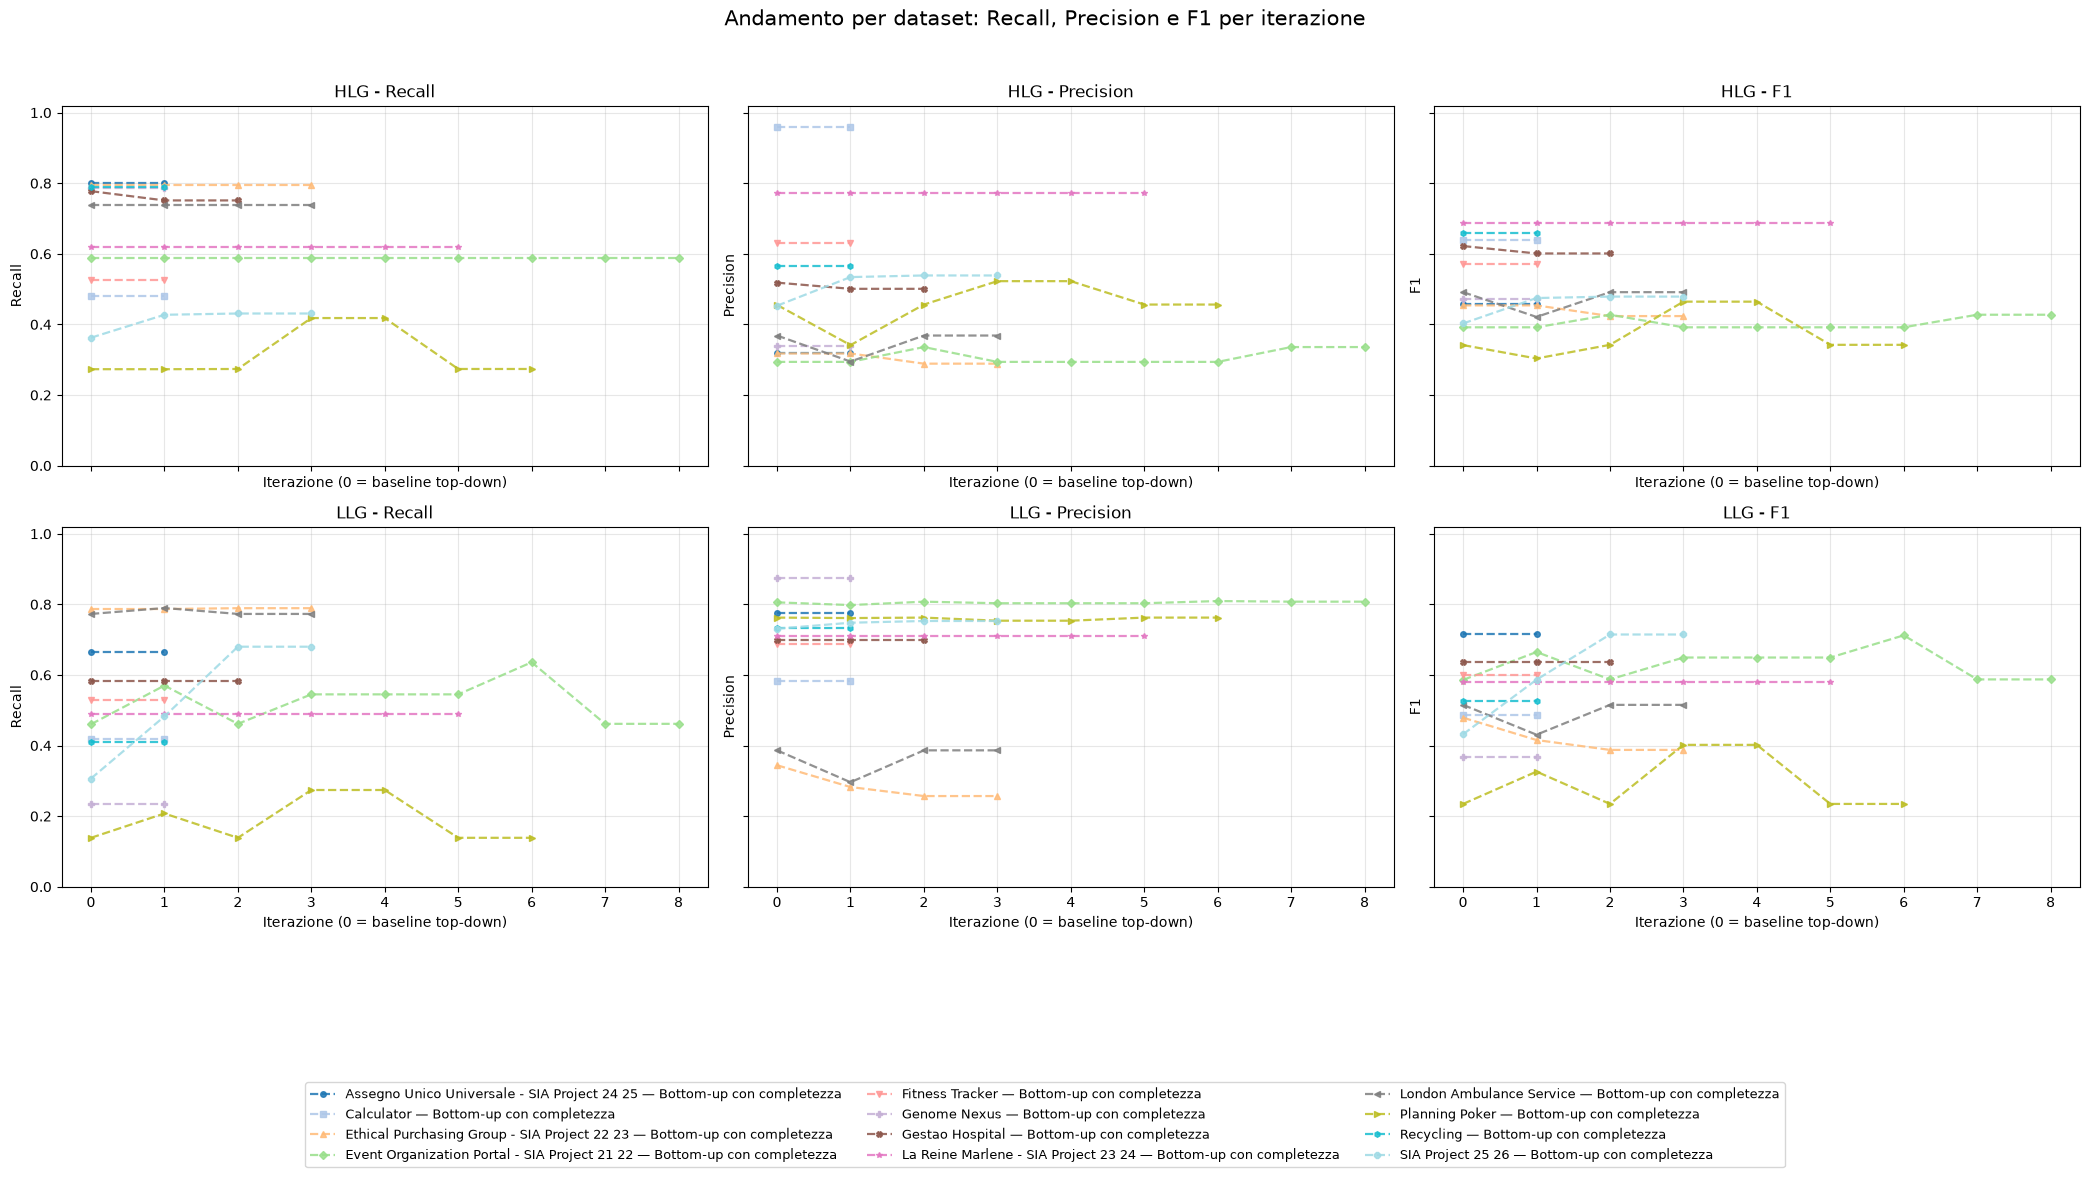

In [11]:
profile_styles = {
    "top_down_plus_bottom_up": {"label": "Bottom-up storico senza completezza", "linestyle": "-"},
    "top_down_plus_bottom_up_plus_completeness": {"label": "Bottom-up con completezza", "linestyle": "--"},
    "top_down_only": {"label": "Solo baseline top-down", "linestyle": "None"},
}

metric_columns = (
    ("recall", "Recall"),
    ("precision", "Precision"),
    ("f1", "F1"),
)
level_rows = (
    ("High-Level Goals", "HLG"),
    ("Low-Level Goals", "LLG"),
)
dataset_names = sorted(iteration_metrics_df["dataset"].unique())
color_map = plt.get_cmap("tab20", max(len(dataset_names), 1))
markers = ("o", "s", "^", "D", "v", "P", "X", "*", "<", ">", "h", "8")
dataset_styles = {
    dataset: {
        "color": color_map(index),
        "marker": markers[index % len(markers)],
    }
    for index, dataset in enumerate(dataset_names)
}
all_iterations = sorted(iteration_metrics_df["iteration"].unique())

detail_fig, detail_axes = plt.subplots(
    2, 3, figsize=(21, 12), sharex=True, sharey=True
)
for row_index, (level, level_label) in enumerate(level_rows):
    level_df = iteration_metrics_df[iteration_metrics_df["level"] == level]
    for column_index, (metric, metric_label) in enumerate(metric_columns):
        axis = detail_axes[row_index, column_index]
        for dataset in dataset_names:
            style = dataset_styles[dataset]
            for profile, profile_style in profile_styles.items():
                dataset_df = level_df[(level_df["dataset"] == dataset) & (level_df["profile"] == profile)].sort_values("iteration")
                if dataset_df.empty:
                    continue
                axis.plot(
                    dataset_df["iteration"], dataset_df[metric],
                    label=f"{dataset} — {profile_style['label']}",
                    color=style["color"], marker=style["marker"],
                    linestyle=profile_style["linestyle"], linewidth=1.6,
                    markersize=4, alpha=0.85,
                )
        axis.set_title(f"{level_label} - {metric_label}")
        axis.set_xlabel("Iterazione (0 = baseline top-down)")
        axis.set_ylabel(metric_label)
        axis.set_ylim(0, 1.02)
        axis.set_xticks(all_iterations)
        axis.grid(True, alpha=0.3)

legend_handles, legend_labels = detail_axes[0, 0].get_legend_handles_labels()
detail_fig.legend(
    legend_handles,
    legend_labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=3,
    fontsize=9,
)
detail_fig.suptitle(
    "Andamento per dataset: Recall, Precision e F1 per iterazione",
    fontsize=15,
)
detail_fig.tight_layout(rect=(0, 0.20, 1, 0.96))
iteration_dataset_chart_path = (
    EVALUATION_DIR / "iteration_metric_trend_by_dataset.png"
)
detail_fig.savefig(
    iteration_dataset_chart_path, dpi=200, bbox_inches="tight"
)
plt.show()
